---
title: "Magnetostatics — Level 2"
short_title: "06 Magnetostatics"
numbering:
  heading_2: true
  equation: true
---

# Magnetostatics

:::{seealso} Math for this topic
- [E-M1: Vector calculus for fields](../math/01-vector-calculus-fields.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 26–27 | Biot–Savart for simple loops, Ampère's law in symmetric cases |
| **2** | **Griffiths, ch. 5–6** | **Div and curl of B, the vector potential A, magnetization** |
| 3 | Jackson, ch. 5 | Multipole expansion of A, boundary-value problems for B, magnetic scalar potential |

The new skill at this level: treating steady currents as sources of a divergence-free field with a curl, described by a vector potential

Math for this topic: E-M1 (vector calculus, curvilinear coordinates).
:::

Workbook example ladder: field on the axis of a loop → A of a solenoid → magnetized sphere in a uniform field. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## The Lorentz Force and Currents

A charge $q$ moving with velocity $\vec{v}$ feels

$$
\vec{F} = q\left(\vec{E} + \vec{v}\times\vec{B}\right) .
$$

The magnetic part is perpendicular to $\vec{v}$, so it **does no work**: it bends paths but never changes speed (the cyclotron circles of the mechanics notes). In a field $B$, a charge circles at $\omega = qB/m$ with radius $mv/(qB)$.

A **current** is moving charge. Its density $\vec{J}$ (current per unit area) for charges of density $\rho$ moving at $\vec{v}$ is $\vec{J} = \rho\vec{v}$, and local charge conservation reads

$$
\nabla\cdot\vec{J} = -\frac{\partial\rho}{\partial t} .
$$ (eq-continuity)

**Magnetostatics** is the regime of steady currents: $\partial\rho/\partial t = 0$, so $\nabla\cdot\vec{J} = 0$, and the fields do not change in time.

## The Biot–Savart Law

Steady currents produce a magnetic field

$$
\vec{B}(\vec{r}) = \frac{\mu_0}{4\pi}\int\frac{\vec{J}(\vec{r}')\times\hat{\mathscr{r}}}{\mathscr{r}^2}\,d\tau'
\qquad\left(\text{for a wire: } \frac{\mu_0I}{4\pi}\int\frac{d\vec{l}'\times\hat{\mathscr{r}}}{\mathscr{r}^2}\right),
$$ (eq-biot-savart)

with $\mu_0 = 4\pi\times10^{-7}$ N/A². It plays the role Coulomb's law plays in electrostatics, with a cross product making $\vec{B}$ circulate around currents rather than point away from them.

::::{prf:example} The field on the axis of a current loop
:label: ex-loop-axis

Find $\vec{B}$ on the axis of a circular loop of radius $a$ carrying current $I$, at height $z$.

:::{dropdown} Solution
Every element $d\vec{l}'$ is perpendicular to the line to the field point, at distance $\sqrt{a^2 + z^2}$. Components perpendicular to the axis cancel around the loop; the axial component of each contribution carries a factor $a/\sqrt{a^2 + z^2}$:

$$
B_z = \frac{\mu_0I}{4\pi}\frac{2\pi a}{a^2 + z^2}\frac{a}{\sqrt{a^2 + z^2}} = \frac{\mu_0Ia^2}{2(a^2 + z^2)^{3/2}} .
$$

At the center, $\mu_0I/2a$. Far away, $\mu_0Ia^2/(2z^3) = \dfrac{\mu_0}{4\pi}\dfrac{2m}{z^3}$ with $m = I\pi a^2$, the axial field of a magnetic dipole.
:::
::::

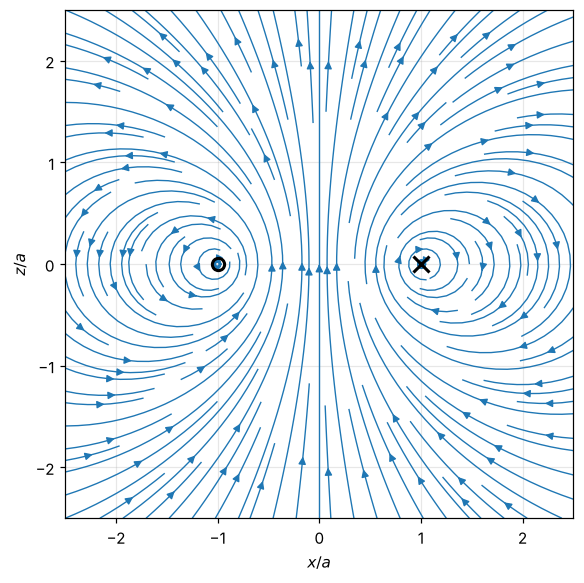

In [2]:
#| label: fig-loop-field
#| caption: Field lines of a current loop (seen edge-on, current into the page on the right and out on the left), from numerical Biot–Savart integration. Every line closes on itself, threading the loop; far away, the pattern matches a dipole.
a = 1.0
N = 240
ph = np.linspace(0, 2 * np.pi, N, endpoint=False)
src = np.c_[a * np.cos(ph), a * np.sin(ph), np.zeros(N)]
dl = np.c_[-np.sin(ph), np.cos(ph), np.zeros(N)] * (2 * np.pi * a / N)
x = np.linspace(-2.5, 2.5, 121); z = np.linspace(-2.5, 2.5, 121)
X, Z = np.meshgrid(x, z)
P = np.stack([X, np.zeros_like(X), Z], axis=-1)
B = np.zeros_like(P)
for s_, d_ in zip(src, dl):
    R = P - s_
    R3 = np.linalg.norm(R, axis=-1, keepdims=True)**3 + 1e-9
    B += np.cross(d_, R) / R3
fig, ax = plt.subplots(figsize=(6, 6))
ax.streamplot(X, Z, B[..., 0], B[..., 2], density=1.5, color="tab:blue", linewidth=0.9)
ax.plot([a], [0], "x", color="k", ms=10, mew=2); ax.plot([-a], [0], "o", color="k", ms=8, mfc="none", mew=2)
ax.set_aspect("equal"); ax.set_xlabel("$x/a$"); ax.set_ylabel("$z/a$"); plt.show()

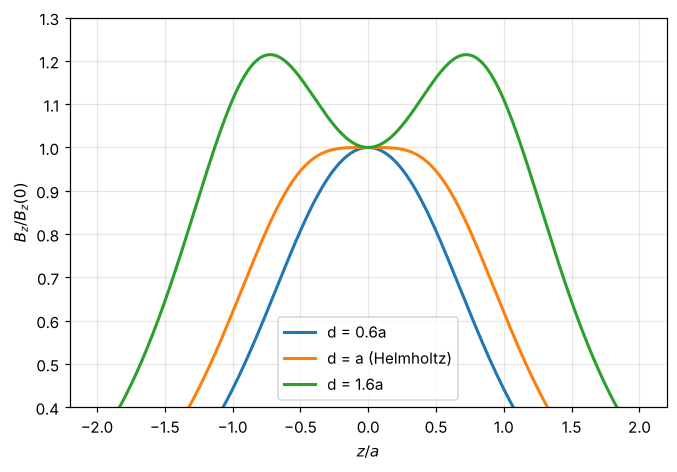

In [3]:
#| label: fig-helmholtz
#| caption: Axial field of two coaxial loops separated by d. At d = a (a Helmholtz pair, middle curve) the field near the center is extremely flat, which is why the arrangement is used to make uniform fields.
z = np.linspace(-2, 2, 500)
Bloop = lambda z0: 1 / (1 + (z - z0)**2)**1.5          # mu0 I a^2 / 2 = 1, a = 1
fig, ax = plt.subplots()
for d_, lab in [(0.6, "d = 0.6a"), (1.0, "d = a (Helmholtz)"), (1.6, "d = 1.6a")]:
    Bz = Bloop(-d_ / 2) + Bloop(d_ / 2)
    ax.plot(z, Bz / Bz[len(z) // 2], lw=2, label=lab)
ax.set_xlabel("$z/a$"); ax.set_ylabel(r"$B_z / B_z(0)$"); ax.set_ylim(0.4, 1.3); ax.legend(); plt.show()

## Divergence and Curl of $\vec{B}$

Taking the divergence and curl of {eq}`eq-biot-savart` (E-M1 identities and the delta function do the work) gives the two field equations of magnetostatics:

$$
\nabla\cdot\vec{B} = 0, \qquad \nabla\times\vec{B} = \mu_0\vec{J} .
$$ (eq-magnetostatics)

- **No magnetic monopoles:** field lines never start or end; they close or go to infinity.
- **Ampère's law:** in integral form, $\oint\vec{B}\cdot d\vec{l} = \mu_0I_{\text{enc}}$. Like Gauss's law, it always holds but **solves** for $\vec{B}$ only with enough symmetry: an infinite straight wire, an infinite plane of current, an infinite solenoid, a toroid.

| Configuration | Field |
|---|---|
| straight wire | $\dfrac{\mu_0I}{2\pi s}\,\hat{\phi}$ |
| infinite sheet, surface current $\vec{K}$ | $\dfrac{\mu_0}{2}\vec{K}\times\hat{n}$ (uniform on each side) |
| long solenoid, $n$ turns per length | $\mu_0nI$ inside, $0$ outside |
| toroid, $N$ turns | $\dfrac{\mu_0NI}{2\pi s}$ inside, $0$ outside |

Comparing with electrostatics ($\nabla\cdot\vec{E} = \rho/\epsilon_0$, $\nabla\times\vec{E} = \vec{0}$), the roles of divergence and curl are exchanged.

### Boundary conditions

Across a surface current $\vec{K}$, the normal component of $\vec{B}$ is continuous and the tangential component jumps:

$$
B_\perp^{\text{above}} = B_\perp^{\text{below}}, \qquad \vec{B}_\parallel^{\text{above}} - \vec{B}_\parallel^{\text{below}} = \mu_0\,\vec{K}\times\hat{n} .
$$

### Exercises

1. A long cylindrical wire of radius $R$ carries current $I$ spread uniformly over its cross-section. Find $B(s)$ inside and outside.
2. Find the force per unit length between two long parallel wires carrying currents $I_1$, $I_2$ a distance $d$ apart. Do parallel currents attract or repel?
3. A proton moves at $3\times10^6$ m/s perpendicular to a 0.5 T field. Find the radius of its orbit.

:::{dropdown} Hints
1. Ampère loop of radius $s$; inside, $I_{\text{enc}} = I s^2/R^2$.
2. Each wire sits in the other's field $\mu_0I/(2\pi d)$; $F = I\,\vec{l}\times\vec{B}$.
3. $r = mv/(qB)$.
:::

:::{dropdown} Answers
1. Inside $B = \dfrac{\mu_0Is}{2\pi R^2}$; outside $B = \dfrac{\mu_0I}{2\pi s}$.
2. $F/L = \dfrac{\mu_0I_1I_2}{2\pi d}$; parallel currents attract.
3. $r = (1.67\times10^{-27})(3\times10^6)/\big((1.6\times10^{-19})(0.5)\big)\approx6.3$ cm.
:::

## The Vector Potential

Since $\nabla\cdot\vec{B} = 0$, E-M1 guarantees $\vec{B} = \nabla\times\vec{A}$ for some vector potential $\vec{A}$. It is not unique: adding any gradient leaves $\vec{B}$ unchanged, so one can always choose $\nabla\cdot\vec{A} = 0$ (the **Coulomb gauge**). Then Ampère's law, with {eq}`eq-curl-curl` from E-M1, becomes

$$
\nabla^2\vec{A} = -\mu_0\vec{J} ,
$$

three Poisson equations, one per Cartesian component, with the familiar solution

$$
\vec{A}(\vec{r}) = \frac{\mu_0}{4\pi}\int\frac{\vec{J}(\vec{r}')}{\mathscr{r}}\,d\tau' .
$$ (eq-vector-potential)

$\vec{A}$ tends to run parallel to the currents that make it, the way $V$ follows the charges.

::::{prf:example} The vector potential of a solenoid
:label: ex-solenoid-A

Find $\vec{A}$ for a long solenoid of radius $R$ with uniform interior field $B$.

:::{dropdown} Solution
By symmetry $\vec{A} = A(s)\hat{\phi}$. Stokes' theorem says $\oint\vec{A}\cdot d\vec{l}$ around a circle equals the magnetic flux through it:

$$
2\pi sA = \begin{cases}\pi s^2B & s < R\\ \pi R^2B & s > R\end{cases}
\quad\Longrightarrow\quad
\vec{A} = \begin{cases}\dfrac{Bs}{2}\hat{\phi} & s < R\\[6pt] \dfrac{BR^2}{2s}\hat{\phi} & s > R\end{cases}
$$

Outside, $\vec{B} = \vec{0}$ but $\vec{A}\ne\vec{0}$. Classically this is harmless, since only $\vec{B}$ acts on charges. In quantum mechanics, electrons passing **outside** the solenoid pick up a phase from $\vec{A}$ that shifts their interference pattern (the Aharonov–Bohm effect), which makes the potentials more than bookkeeping.
:::
::::

In [4]:
# Check the solenoid A: its curl in cylindrical coordinates gives B inside and 0 outside
s, Bsym, R = sp.symbols("s B R", positive=True)
curl_z = lambda Aphi: sp.simplify(sp.diff(s * Aphi, s) / s)       # (curl A)_z for A = A_phi(s) phi-hat
print("inside :", curl_z(Bsym * s / 2))
print("outside:", curl_z(Bsym * R**2 / (2 * s)))

inside : B
outside: 0


## Magnetic Dipoles and Magnetized Matter

Far from any small current loop, the field is that of a **magnetic dipole** $\vec{m} = I\vec{a}$ (current times vector area), with the same shape as an electric dipole's field:

$$
\vec{A}_{\text{dip}} = \frac{\mu_0}{4\pi}\frac{\vec{m}\times\hat{r}}{r^2}, \qquad
\vec{B}_{\text{dip}} = \frac{\mu_0}{4\pi r^3}\left[3(\vec{m}\cdot\hat{r})\hat{r} - \vec{m}\right] .
$$

In a field, a magnetic dipole feels torque $\vec{m}\times\vec{B}$ and has energy $-\vec{m}\cdot\vec{B}$.

Atoms carry magnetic dipoles (from electron orbits and spins). A material's **magnetization** $\vec{M}$ is its dipole moment per unit volume, and just as polarization produced bound charge, magnetization produces **bound currents**:

$$
\vec{J}_b = \nabla\times\vec{M}, \qquad \vec{K}_b = \vec{M}\times\hat{n} .
$$

Separating these from the **free** currents you control defines $\vec{H} = \vec{B}/\mu_0 - \vec{M}$, with $\nabla\times\vec{H} = \vec{J}_f$. For linear materials $\vec{M} = \chi_m\vec{H}$ and $\vec{B} = \mu\vec{H}$ with $\mu = \mu_0(1 + \chi_m)$:

| Type | $\chi_m$ | Mechanism |
|---|---|---|
| diamagnet | small, negative ($\sim-10^{-5}$) | orbits respond to oppose the field |
| paramagnet | small, positive ($\sim10^{-5}$ to $10^{-3}$) | spins align with the field |
| ferromagnet | huge and field-dependent | spins align collectively, with memory (hysteresis) |

A **uniformly magnetized sphere** has a uniform interior field $\vec{B} = \tfrac23\mu_0\vec{M}$ and a pure dipole field outside, the magnetic twin of the uniformly polarized sphere.

### Exercises

1. Find the magnetic dipole moment of a square loop of side $L$ carrying current $I$, and its far-field strength on the axis.
2. A long solenoid with $n$ turns per length is filled with a linear material of susceptibility $\chi_m$. Find $\vec{H}$, $\vec{B}$, $\vec{M}$ and the bound surface current.
3. Show that $\vec{A} = \tfrac12\vec{B}_0\times\vec{r}$ is a vector potential for a uniform field and that it satisfies the Coulomb gauge.

:::{dropdown} Hints
1. $m = IL^2$; use the dipole field on its axis.
2. Ampère's law for $\vec{H}$ gives $H = nI$, using only free current.
3. Compute $\nabla\times$ and $\nabla\cdot$ of $\tfrac12\vec{B}_0\times\vec{r}$ (E-M1 product rules).
:::

:::{dropdown} Answers
1. $m = IL^2$, and on the axis far away $B = \dfrac{\mu_0}{4\pi}\dfrac{2IL^2}{z^3}$.
2. $H = nI$, $B = \mu_0(1 + \chi_m)nI$, $M = \chi_mnI$, and $K_b = \chi_mnI$ circulating like the windings (same sense for a paramagnet, opposite for a diamagnet).
3. $\nabla\times\vec{A} = \vec{B}_0$ (shown in E-M1), and $\nabla\cdot(\vec{B}_0\times\vec{r}) = \vec{r}\cdot(\nabla\times\vec{B}_0) - \vec{B}_0\cdot(\nabla\times\vec{r}) = 0$.
:::

## Summary

- $\vec{F} = q(\vec{E} + \vec{v}\times\vec{B})$; magnetic forces do no work.
- Steady currents produce $\vec{B}$ by Biot–Savart; $\nabla\cdot\vec{B} = 0$ and $\nabla\times\vec{B} = \mu_0\vec{J}$, with Ampère's law solving symmetric cases.
- $\vec{B} = \nabla\times\vec{A}$; in Coulomb gauge each component of $\vec{A}$ obeys a Poisson equation, and $\vec{A}$ can be nonzero where $\vec{B}$ vanishes.
- Small loops are magnetic dipoles, with the same field shape as electric dipoles.
- Magnetization produces bound currents; $\vec{H}$ tracks free current, and $\vec{B} = \mu\vec{H}$ in linear media.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.